# Гауссовый KAN со сплайновыми рёбрами
## Первый обучаемый прототип · сеть 2 → 3 → 1 · 8 октября 2026

**Задача:** проверить, может ли сеть обучиться нелинейному преобразованию двух 2D-гауссиан
в одну, сохраняя гауссово состояние во всех слоях.

**Что реализовано:** B-сплайны с нуля; отдельные параметры на каждом гауссовом ребре;
состояние-зависимый аффинный транспорт; арифметическое усреднение средних и ковариаций;
обучение по $W_2^2$; проверки формул и градиентов; отдельные train / validation / test.

**Границы эксперимента:** это координатная сплайновая параметризация гауссова ребра.
Это не доказательство обобщения теоремы Колмогорова–Арнольда, новизны или преимуществ BW.
В агрегации нет графовой свёртки или BW-барицентра. Здесь нет CAD и обучения на реальных данных.
Сохранённые результаты относятся к одному seed и одной синтетической задаче.

**Запуск:** Python 3.11+, `pip install -r requirements.txt`, затем `jupyter lab` и
**Restart Kernel → Run All**. В Colab можно использовать `%pip install torch numpy matplotlib`.
Все определения находятся в этой тетрадке; соседние Python-файлы и интернет для данных не нужны.
Вычисления по умолчанию выполняются на CPU в float64. Число эпох и размеры выборок меняются в первой ячейке.

**Сохранённый контрольный запуск:** 2520 обучаемых параметров; test W₂² = 0.000523 против 0.136688 у простого среднего входных параметров. Минимальное собственное значение выходной ковариации на test: 0.328. Это один seed и синтетическая задача; сравнения с обученным MLP пока нет.

In [2]:
import copy
import math
import time
import platform
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

SEED = 42
DEVICE = torch.device('cuda')  # При желании: torch.device('cuda')
DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'figure.dpi':115})
BLUE, ORANGE, GREEN = '#2563EB', '#EA580C', '#0D9488'
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__)
print('Device:', DEVICE, '| dtype:', DTYPE, '| seed:', SEED)

# Параметры эксперимента. Менять до Run All.
N_TRAIN, N_VAL, N_TEST = 2048, 512, 1024
BATCH_SIZE, EPOCHS = 256, 180
LR, GRID_INTERVALS, DEGREE = 0.006, 8, 3



Python: 3.12.13 | PyTorch: 2.14.1+cu130
Device: cuda | dtype: torch.float64 | seed: 42


## 1. Какое состояние проходит через сеть

Узел хранит $G=\mathcal N(\mu,\Sigma)$ с $\mu\in\mathbb R^2$ и $\Sigma\succ0$.
Храним tensors `mu: [batch, nodes, 2]`, `cov: [batch, nodes, 2, 2]`.
Для вычисления функции ребра используем обратимые координаты
$$z(G)=(\mu_1,\mu_2,\log L_{11},L_{21},\log L_{22}),\qquad\Sigma=LL^\top.$$
Пять координат сохраняют всю информацию. Затем фиксированное $x_s=\tanh(z_s/c_s)$
помещает аргументы сплайнов в $(-1,1)$. Масштабы $c_s$ заданы вручную до обучения,
не оцениваются по тестовой выборке. Сжатие tanh может ухудшить экстраполяцию далеко за обучающими диапазонами.

**2D-формула loss.** Для положительно определённых матриц размера 2 × 2:
$$\operatorname{tr}\sqrt{\Sigma_p^{1/2}\Sigma_q\Sigma_p^{1/2}}
=\sqrt{\operatorname{tr}(\Sigma_p\Sigma_q)+2\sqrt{\det\Sigma_p\det\Sigma_q}}.$$
Поэтому $W_2^2=\|\mu_p-\mu_q\|^2+\operatorname{tr}\Sigma_p+
\operatorname{tr}\Sigma_q-2\operatorname{tr}\sqrt{\Sigma_p^{1/2}\Sigma_q\Sigma_p^{1/2}}$.
Это точная формула, не диагональное приближение. Она позволяет обходиться без
дифференцирования собственных векторов в loss. Для 3D этот код loss надо заменить.

**Базис.** Используем кубические B-сплайны, 8 интервалов и открытый вектор узлов.
Получается 11 базисных функций на координату. Узлы фиксированы; расширения сетки и pruning в v1 нет.

In [4]:
def sym(x):
    return (x + x.transpose(-1, -2)) * 0.5

def encode_gaussian(mu, cov):
    L = torch.linalg.cholesky(cov)
    return torch.stack((mu[...,0], mu[...,1], L[...,0,0].log(),
                        L[...,1,0], L[...,1,1].log()), dim=-1)

def w2_parts(mu_p, cov_p, mu_q, cov_q):
    """Точная 2D-формула W2²; последние размерности (...,2), (...,2,2)."""
    mean_term = (mu_p - mu_q).square().sum(dim=-1)
    det_p = torch.linalg.det(cov_p)
    det_q = torch.linalg.det(cov_q)
    # SPD проверяется отдельно: clamp служит лишь численной защитой sqrt.
    tiny = torch.finfo(cov_p.dtype).tiny
    tr_prod = (cov_p * cov_q.transpose(-1,-2)).sum(dim=(-1,-2))
    tr_root = torch.sqrt((tr_prod + 2*torch.sqrt((det_p*det_q).clamp_min(tiny))).clamp_min(tiny))
    tr_p = cov_p.diagonal(dim1=-2,dim2=-1).sum(-1)
    tr_q = cov_q.diagonal(dim1=-2,dim2=-1).sum(-1)
    cov_term = (tr_p + tr_q - 2*tr_root).clamp_min(0)
    return mean_term, cov_term

def gaussian_loss(pred, target):
    mean, covariance = w2_parts(*pred, *target)
    return (mean + covariance).mean()

class CubicBSplineBasis(nn.Module):
    """Рекурсия Кокса-де Бура, открытый равномерный вектор узлов на [-1,1]."""
    def __init__(self, intervals=8, degree=3):
        super().__init__()
        self.degree = degree
        grid = torch.linspace(-1, 1, intervals+1)
        knots = torch.cat((grid[:1].repeat(degree), grid, grid[-1:].repeat(degree)))
        self.register_buffer('knots', knots)
        self.n_basis = len(knots) - degree - 1

    def forward(self, x):
        t = self.knots
        # x всегда tanh(z/scale); clamp также определяет значение у правой границы.
        x = x.clamp(-1+1e-10, 1-1e-10).unsqueeze(-1)
        B = ((x >= t[:-1]) & (x < t[1:])).to(x.dtype)
        for p in range(1, self.degree+1):
            count = len(t)-p-1
            left_den = t[p:p+count] - t[:count]
            right_den = t[p+1:p+1+count] - t[1:1+count]
            left = (x-t[:count])/left_den.clamp_min(1e-15)
            right = (t[p+1:p+1+count]-x)/right_den.clamp_min(1e-15)
            B = (left * B[...,:count] * (left_den>0) +
                 right * B[...,1:count+1] * (right_den>0))
        return B



## 2. Ребро и агрегация

На каждом внешнем ребре $i\to j$ находятся 25 скалярных сплайнов:
$$q_r(z)=c_r+\sum_{s=1}^{5}\sum_{k=1}^{11}a_{rsk}B_k(x_s),\quad r=1,\ldots,5.$$
Первые два выхода задают сдвиг $b$. Три оставшихся задают симметричную матрицу $S$.
Для численной устойчивости в этой версии используем ограничение
$s_r=0.6\tanh(q_r/0.6)$; это явное ограничение амплитуды одного шага, а не свойство BW.
Сдвиг $b$ не ограничиваем.

$$A=e^S,\qquad\widetilde\mu_{ji}=\mu_i+b_{ji}(G_i),\qquad
\widetilde\Sigma_{ji}=A_{ji}(G_i)\Sigma_iA_{ji}(G_i)^\top.$$

Матричная экспонента симметричной $S$ даёт SPD-матрицу $A$. Это оптимальный квадратичный транспорт
между входной и полученной выходной гауссианами, но не гарантия правильного предсказания цели.
Аффинность относится к точкам при фиксированном $G$; функция $G\mapsto\widetilde G$ нелинейна.

**Агрегация:** $\mu'_j=\frac1n\sum_i\widetilde\mu_{ji}$,
$\Sigma'_j=\frac1n\sum_i\widetilde\Sigma_{ji}$.
Это среднее параметров, не сумма независимых векторов, не смесь и не BW-барицентр.
Положительные веса сохраняют SPD. Мы не добавляем скрытый jitter к выходу.

Каждое внешнее ребро имеет собственные параметры; сеть не предполагает перестановочную
эквивариантность входных гауссиан. В задаче входы 0 и 1 имеют фиксированные роли.
Небольшая случайная инициализация около тождественного транспорта предотвращает
полную симметрию трёх скрытых узлов. Обучаются только коэффициенты и смещения сплайнов.

In [5]:
class GaussianSplineLayer(nn.Module):
    def __init__(self, n_in, n_out, intervals=GRID_INTERVALS, degree=DEGREE):
        super().__init__()
        self.n_in, self.n_out = n_in, n_out
        self.basis = CubicBSplineBasis(intervals, degree)
        # out-node, in-node, output-parameter, input-coordinate, basis-function
        self.coeff = nn.Parameter(0.015*torch.randn(n_out,n_in,5,5,self.basis.n_basis))
        self.bias = nn.Parameter(torch.zeros(n_out,n_in,5))
        self.register_buffer('coord_scale',torch.tensor([1.5,1.5,0.7,0.7,0.7]))
        self.s_limit = 0.6

    def forward(self, mu, cov, return_messages=False):
        z = encode_gaussian(mu,cov)                  # [B, in, 5]
        x = torch.tanh(z/self.coord_scale)           # fixed map into (-1,1)
        basis = self.basis(x)                       # [B, in, 5, K]
        q = torch.einsum('biqk,oirqk->boir',basis,self.coeff) + self.bias
        b = q[...,:2]                              # [B, out, in, 2]
        s = self.s_limit*torch.tanh(q[...,2:]/self.s_limit)
        S = torch.stack((s[...,0],s[...,1],s[...,1],s[...,2]),-1).reshape(*s.shape[:-1],2,2)
        A = torch.linalg.matrix_exp(S)
        msg_mu = mu[:,None,:,:] + b
        msg_cov = sym(A @ cov[:,None,:,:,:] @ A.transpose(-1,-2))
        # Равные фиксированные веса, усреднение параметров по входящим рёбрам.
        new_state = (msg_mu.mean(dim=2), msg_cov.mean(dim=2))
        if return_messages:
            return new_state, (msg_mu,msg_cov), (b,S,A)
        return new_state

class GaussianSplineKAN(nn.Module):
    def __init__(self, widths=(2,3,1)):
        super().__init__()
        self.widths = widths
        self.layers = nn.ModuleList([GaussianSplineLayer(a,b) for a,b in zip(widths[:-1],widths[1:])])

    def forward(self, mu, cov, return_states=False):
        states=[(mu,cov)]
        for layer in self.layers:
            mu,cov=layer(mu,cov)
            states.append((mu,cov))
        return states if return_states else (mu,cov)

torch.manual_seed(SEED)
model = GaussianSplineKAN().to(DEVICE)
print(model)
print('Обучаемых параметров:',sum(p.numel() for p in model.parameters()))



GaussianSplineKAN(
  (layers): ModuleList(
    (0-1): 2 x GaussianSplineLayer(
      (basis): CubicBSplineBasis()
    )
  )
)
Обучаемых параметров: 2520


## 3. Данные и независимая целевая функция

Каждый пример содержит две независимым образом сгенерированные гауссианы.
Компоненты средних равномерны на $[-1,1]$; диагональ фактора Холецкого на $[0.55,1.15]$;
внедиагональный элемент на $[-0.65,0.65]$. Ковариации полные, ориентации различаются.

Цель задаётся функцией `target_function`, напрямую через среднее и положительно определённую
ковариацию. Она не вызывает наши рёбра, агрегацию или сплайны. В неё включены синус,
произведения координат разных входов, зависимость среднего от ковариации и формы от средних.
Ковариация цели строится как $L_*L_*^\top$ с положительной диагональю $L_*$.

Train, validation и test генерируются разными seed из одного распределения.
Это проверка интерполяционного обобщения. Она не проверяет выход за диапазон или перенос на CAD.
Validation выбирает эпоху; test используется для итоговой оценки после обучения.

In [6]:
def generate_inputs(n, n_nodes, seed):
    gen=torch.Generator(device='cpu').manual_seed(seed)
    mu=2*torch.rand(n,n_nodes,2,generator=gen)-1
    a=0.55+0.6*torch.rand(n,n_nodes,generator=gen)
    d=0.55+0.6*torch.rand(n,n_nodes,generator=gen)
    off=0.65*(2*torch.rand(n,n_nodes,generator=gen)-1)
    zero=torch.zeros_like(a)
    L=torch.stack((a,zero,off,d),dim=-1).reshape(n,n_nodes,2,2)
    return mu.to(DEVICE),(L@L.transpose(-1,-2)).to(DEVICE)

def target_function(mu,cov):
    """Учитель задан аналитически, не использует наш сплайновый слой."""
    u,v=mu[:,0,:],mu[:,1,:]
    c,d=cov[:,0,:,:],cov[:,1,:,:]
    m0=0.5*(u[:,0]+v[:,0])+0.30*torch.sin(1.4*u[:,1])+0.15*v[:,0]*v[:,1]+0.10*(c[:,0,0]-d[:,0,0])
    m1=0.5*(u[:,1]+v[:,1])+0.25*torch.sin(1.2*v[:,0])+0.12*u[:,0]*v[:,1]+0.10*(c[:,0,1]+d[:,0,1])
    l00=0.75+0.12*torch.tanh(u[:,0]+v[:,1])+0.10*(c[:,0,0]+d[:,0,0])
    l11=0.65+0.10*torch.tanh(u[:,1]-v[:,0])+0.08*(c[:,1,1]+d[:,1,1])
    l10=0.20*torch.sin(u[:,0]-v[:,1])+0.15*(c[:,0,1]+d[:,0,1])
    L=torch.stack((l00,torch.zeros_like(l00),l10,l11),-1).reshape(-1,2,2)
    return torch.stack((m0,m1),-1)[:,None,:],(L@L.transpose(-1,-2))[:,None,:,:]

def make_dataset(n,seed):
    inputs=generate_inputs(n,2,seed)
    return inputs,target_function(*inputs)

train=make_dataset(N_TRAIN,101)
val=make_dataset(N_VAL,202)
test=make_dataset(N_TEST,303)
for name,(x,y) in [('train',train),('val',val),('test',test)]:
    print(name,'μ:',tuple(x[0].shape),'Σ:',tuple(x[1].shape),'target μ:',tuple(y[0].shape))



train μ: (2048, 2, 2) Σ: (2048, 2, 2, 2) target μ: (2048, 1, 2)
val μ: (512, 2, 2) Σ: (512, 2, 2, 2) target μ: (512, 1, 2)
test μ: (1024, 2, 2) Σ: (1024, 2, 2, 2) target μ: (1024, 1, 2)


## 4. Проверки до обучения

Проверяем разбиение единицы B-сплайнами, формулу W₂² относительно общей спектральной формулы,
тождественное ребро и SPD агрегации. `gradcheck` сравнивает autograd с конечными разностями
по среднему и фактору ковариации входа. Для точки проверки избегаем узлов сплайна.

In [7]:
def sqrt_spd_reference(cov):
    values,vectors=torch.linalg.eigh(cov)
    return (vectors*values.sqrt().unsqueeze(-2))@vectors.transpose(-1,-2)

basis_check=CubicBSplineBasis()
grid=torch.linspace(-0.999,0.999,101)
B=basis_check(grid)
assert torch.all(B>=-1e-12) and torch.allclose(B.sum(-1),torch.ones_like(grid),atol=1e-10)

mu_check,cov_check=generate_inputs(12,2,999)
mp,cp=mu_check[:,0],cov_check[:,0]
mq,cq=mu_check[:,1],cov_check[:,1]
root=sqrt_spd_reference(cp)
cross=sqrt_spd_reference(root@cq@root)
ref_cov=(cp+cq-2*cross).diagonal(dim1=-2,dim2=-1).sum(-1)
_,actual_cov=w2_parts(mp,cp,mq,cq)
assert torch.allclose(actual_cov,ref_cov,atol=1e-9)
assert gaussian_loss((mp,cp),(mp,cp)).item()<1e-10

identity_layer=GaussianSplineLayer(2,3).to(DEVICE)
with torch.no_grad():
    identity_layer.coeff.zero_();identity_layer.bias.zero_()
    out, messages, (_,_,A)=identity_layer(mu_check,cov_check,True)
assert torch.allclose(A,torch.eye(2,device=DEVICE).expand_as(A),atol=1e-12)
assert torch.allclose(out[0],mu_check.mean(1,keepdim=True).expand(-1,3,-1))
assert torch.allclose(out[1],cov_check.mean(1,keepdim=True).expand(-1,3,-1,-1))
assert torch.linalg.eigvalsh(out[1]).min()>0

# Градиент проверяем и по μ, и по фактору ковариации, вдали от узлов сплайна.
edge_grad=GaussianSplineLayer(1,1).to(DEVICE)
mg=torch.tensor([[[0.21,-0.37]]],device=DEVICE,requires_grad=True)
lg=torch.tensor([[[[0.93,0.0],[0.23,0.81]]]],device=DEVICE,requires_grad=True)
assert torch.autograd.gradcheck(lambda m,L: edge_grad(m,L@L.transpose(-1,-2)),
                               (mg,lg),eps=1e-6,atol=1e-4,rtol=1e-3)
print('✓ Базис: неотрицательность и разбиение единицы')
print('✓ 2D W₂² совпадает с общей спектральной формулой; W₂²(G,G)=0')
print('✓ Нулевое ребро тождественно; узел усредняет параметры; SPD сохраняется')
print('✓ Autograd совпадает с конечными разностями по входному состоянию')



✓ Базис: неотрицательность и разбиение единицы
✓ 2D W₂² совпадает с общей спектральной формулой; W₂²(G,G)=0
✓ Нулевое ребро тождественно; узел усредняет параметры; SPD сохраняется
✓ Autograd совпадает с конечными разностями по входному состоянию


## 5. Обучение

Loss — средний $W_2^2$, без дополнительных регуляризаторов. Adam, убывающий learning rate,
ограничение нормы градиента 5. Сохраняем параметры лучшей эпохи по validation.
Train loss на графике — среднее batch-loss в течение эпохи, validation — оценка в конце эпохи.
В нулевой точке обе ошибки вычислены до обучения.

Сначала обучаем отдельное ребро на постоянном SPD-аффинном преобразовании, которое оно
точно умеет представить. Затем обучаем всю сеть на нелинейной задаче. Такой порядок отделяет
ошибки реализации транспорта от ограничений выразимости полной модели.

In [8]:
@torch.no_grad()
def evaluate(net,data,batch_size=512):
    x,y=data
    mean_errors=[];cov_errors=[];mineigs=[]
    net.eval()
    for start in range(0,len(x[0]),batch_size):
        sl=slice(start,start+batch_size)
        pred=net(x[0][sl],x[1][sl])
        a,b=w2_parts(*pred,y[0][sl],y[1][sl])
        mean_errors.append(a.flatten());cov_errors.append(b.flatten())
        mineigs.append(torch.linalg.eigvalsh(pred[1]).min())
    a=torch.cat(mean_errors);b=torch.cat(cov_errors)
    return {'w2':(a+b).mean().item(),'mean':a.mean().item(),'cov':b.mean().item(),
            'min_eig':torch.stack(mineigs).min().item()}

def fit(net,train_data,val_data,epochs,lr=LR,seed=42,verbose_every=30):
    opt=torch.optim.Adam(net.parameters(),lr=lr)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epochs,eta_min=lr/10)
    gen=torch.Generator(device='cpu').manual_seed(seed)
    x,y=train_data;n=len(x[0]);history=[]
    best=math.inf;best_state=None;best_epoch=None
    before=evaluate(net,val_data)
    history.append({'epoch':0,'train':evaluate(net,train_data)['w2'],'val':before['w2'],
                    'val_mean':before['mean'],'val_cov':before['cov']})
    start=time.perf_counter()
    for epoch in range(1,epochs+1):
        net.train();running=0.
        order=torch.randperm(n,generator=gen).to(DEVICE)
        for ids in order.split(BATCH_SIZE):
            opt.zero_grad(set_to_none=True)
            pred=net(x[0][ids],x[1][ids])
            loss=gaussian_loss(pred,(y[0][ids],y[1][ids]))
            if not torch.isfinite(loss):raise RuntimeError('Нечисловой loss')
            loss.backward()
            norm=torch.nn.utils.clip_grad_norm_(net.parameters(),max_norm=5.,error_if_nonfinite=True)
            opt.step();running+=loss.item()*len(ids)
        scheduler.step()
        scores=evaluate(net,val_data)
        history.append({'epoch':epoch,'train':running/n,'val':scores['w2'],
                        'val_mean':scores['mean'],'val_cov':scores['cov']})
        if scores['w2']<best:
            best=scores['w2'];best_state=copy.deepcopy(net.state_dict());best_epoch=epoch
        if epoch==1 or epoch%verbose_every==0 or epoch==epochs:
            print(f"epoch {epoch:3d} | train {running/n:.6f} | val {scores['w2']:.6f}",flush=True)
    net.load_state_dict(best_state);net.eval()
    print(f'Выбран epoch {best_epoch} по validation; время {time.perf_counter()-start:.1f} с',flush=True)
    return history,best_epoch



### 5.1. Проверка отдельного ребра на известном аффинном преобразовании

In [9]:
def affine_dataset(n,seed):
    x=generate_inputs(n,1,seed)
    S=torch.tensor([[0.18,0.09],[0.09,-0.12]],device=DEVICE)
    A=torch.linalg.matrix_exp(S)
    b=torch.tensor([0.35,-0.25],device=DEVICE)
    return x,(x[0]+b,sym(A@x[1]@A.T))

torch.manual_seed(7)
affine_model=GaussianSplineKAN((1,1)).to(DEVICE)
affine_train=affine_dataset(512,701)
affine_val=affine_dataset(256,702)
affine_test=affine_dataset(256,703)
affine_initial=evaluate(affine_model,affine_test)
affine_history,_=fit(affine_model,affine_train,affine_val,epochs=65,lr=0.008,seed=7,verbose_every=25)
affine_final=evaluate(affine_model,affine_test)
print('Отдельное ребро: test W₂² до / после:',affine_initial['w2'],affine_final['w2'])
assert affine_final['w2']<affine_initial['w2']/10, 'Проверьте обучение отдельного ребра'



epoch   1 | train 0.193999 | val 0.095173
epoch  25 | train 0.000617 | val 0.000595
epoch  50 | train 0.000033 | val 0.000036
epoch  65 | train 0.000029 | val 0.000032
Выбран epoch 65 по validation; время 1.2 с
Отдельное ребро: test W₂² до / после: 0.23562647345339874 3.136078866578322e-05


### 5.2. Основной эксперимент с двумя входами и одним выходом

In [10]:
torch.manual_seed(SEED)
model=GaussianSplineKAN((2,3,1)).to(DEVICE)
initial_state=copy.deepcopy(model.state_dict())
history,best_epoch=fit(model,train,val,epochs=EPOCHS,seed=SEED)



epoch   1 | train 0.096446 | val 0.065351
epoch  30 | train 0.001599 | val 0.001868
epoch  60 | train 0.000731 | val 0.000898
epoch  90 | train 0.000533 | val 0.000677
epoch 120 | train 0.000453 | val 0.000584
epoch 150 | train 0.000419 | val 0.000551
epoch 180 | train 0.000404 | val 0.000537
Выбран epoch 179 по validation; время 17.5 с


## 6. Итоговые метрики

Сравниваем обученную модель со случайной инициализацией и простым средним входных параметров.
Последнее — диагностический baseline без обучения, **не сильный конкурент MLP/KAN**.
Раздельные слагаемые loss показывают, не скрывает ли улучшение центра плохое предсказание формы.
Минимальное собственное значение выходной ковариации должно быть положительным.

Итог на независимом test:
Среднее входных параметров   W₂²=0.136688; μ-term=0.070132; Σ-term=0.066557
Случайная инициализация      W₂²=0.137684; μ-term=0.069330; Σ-term=0.068354
Обученная сеть               W₂²=0.000523; μ-term=0.000172; Σ-term=0.000351
Снижение W₂² относительно простого среднего: 99.6%
Минимальное собственное значение выходной Σ: 0.3278921613530198


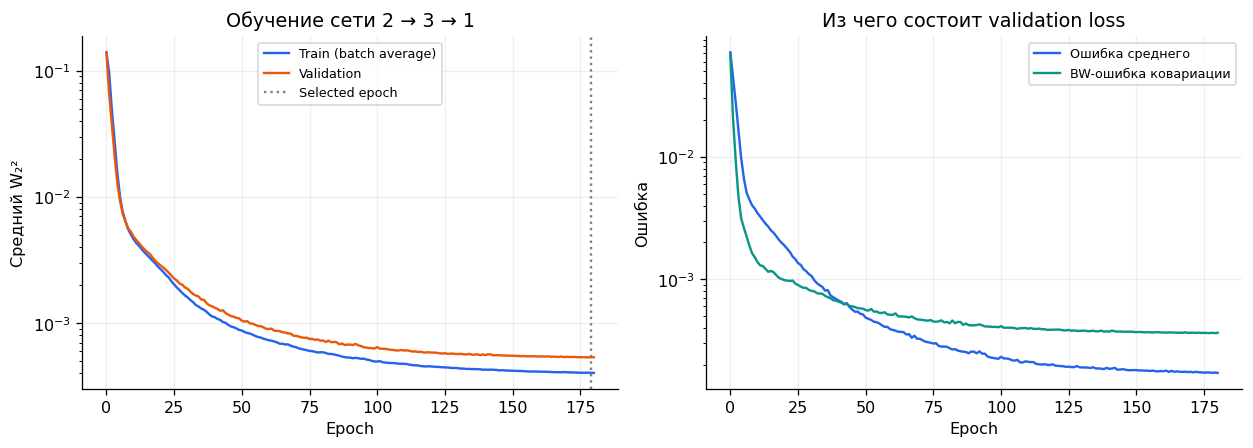

In [9]:
# Test используется для итоговой оценки, не для выбора эпохи.
initial_model=GaussianSplineKAN((2,3,1)).to(DEVICE)
initial_model.load_state_dict(initial_state)
initial_scores=evaluate(initial_model,test)
final_scores=evaluate(model,test)
baseline=(test[0][0].mean(1,keepdim=True),test[0][1].mean(1,keepdim=True))
bm,bc=w2_parts(*baseline,*test[1])
baseline_scores={'w2':(bm+bc).mean().item(),'mean':bm.mean().item(),'cov':bc.mean().item()}
print('Итог на независимом test:')
for name,score in [('Среднее входных параметров',baseline_scores),('Случайная инициализация',initial_scores),('Обученная сеть',final_scores)]:
    print(f"{name:28s} W₂²={score['w2']:.6f}; μ-term={score['mean']:.6f}; Σ-term={score['cov']:.6f}")
print(f"Снижение W₂² относительно простого среднего: {100*(1-final_scores['w2']/baseline_scores['w2']):.1f}%")
print('Минимальное собственное значение выходной Σ:',final_scores['min_eig'])
assert final_scores['min_eig']>0 and np.isfinite(final_scores['w2'])

fig,axes=plt.subplots(1,2,figsize=(11,4))
epochs=[h['epoch'] for h in history]
axes[0].semilogy(epochs,[h['train'] for h in history],label='Train (batch average)',color=BLUE)
axes[0].semilogy(epochs,[h['val'] for h in history],label='Validation',color=ORANGE)
axes[0].axvline(best_epoch,color='gray',ls=':',label='Selected epoch')
axes[0].set(title='Обучение сети 2 → 3 → 1',xlabel='Epoch',ylabel='Средний W₂²')
axes[1].semilogy(epochs,[h['val_mean'] for h in history],label='Ошибка среднего',color=BLUE)
axes[1].semilogy(epochs,[h['val_cov'] for h in history],label='BW-ошибка ковариации',color=GREEN)
axes[1].set(title='Из чего состоит validation loss',xlabel='Epoch',ylabel='Ошибка')
for ax in axes:ax.grid(alpha=0.2);ax.legend(fontsize=8)
plt.tight_layout();plt.show()



## 7. Что сеть передаёт между слоями

На первых шести тестовых примерах сравниваем цели и предсказания без выбора удачных случаев.
Эллипсы имеют радиус Махаланобиса 2; это не условная «95%-область».
Затем показываем все состояния примера №0 в сети и распределение собственных значений
на первых 128 тестовых примерах. Скрытые гауссианы — обученные представления: они не обязаны
быть физическими частями объекта или интерпретируемыми CAD-блобами.

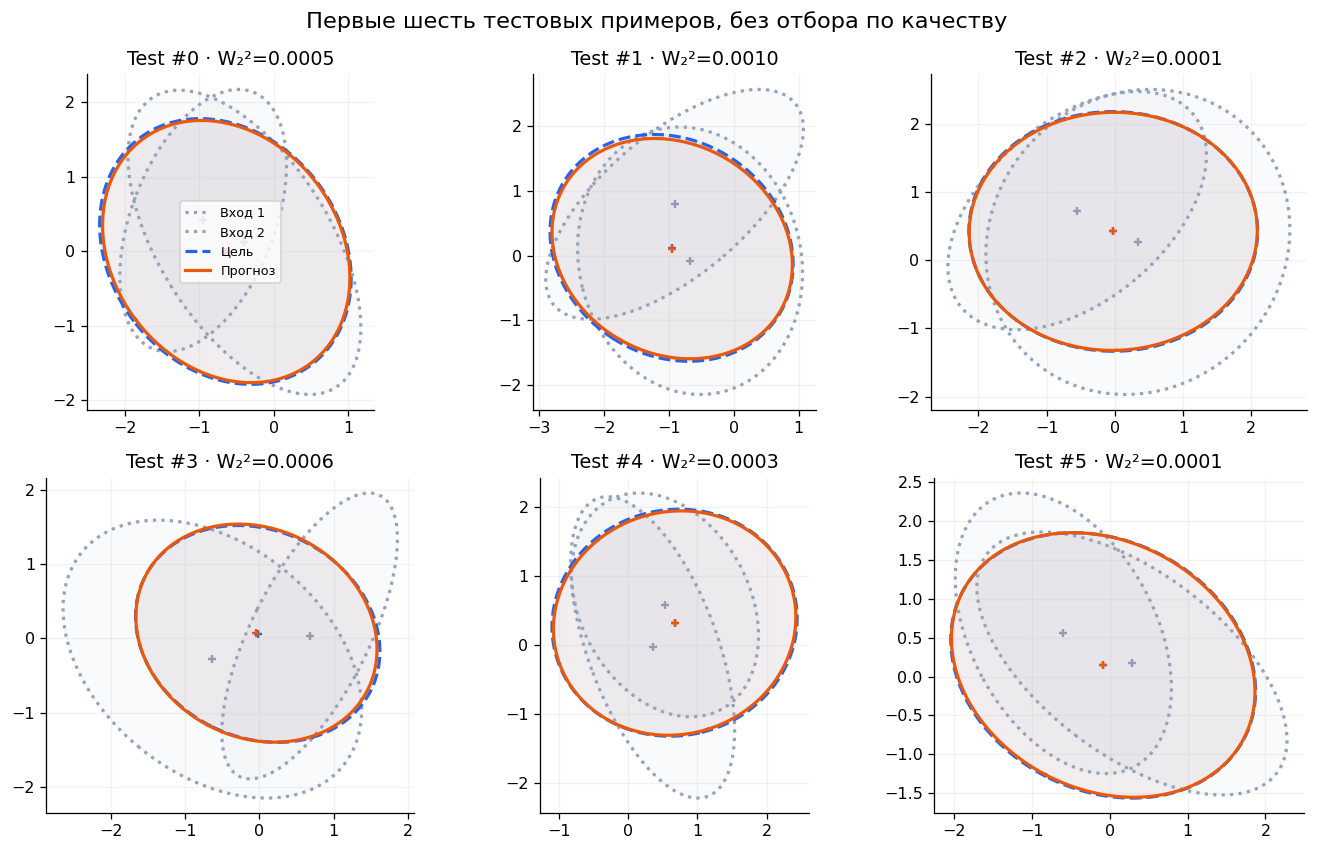

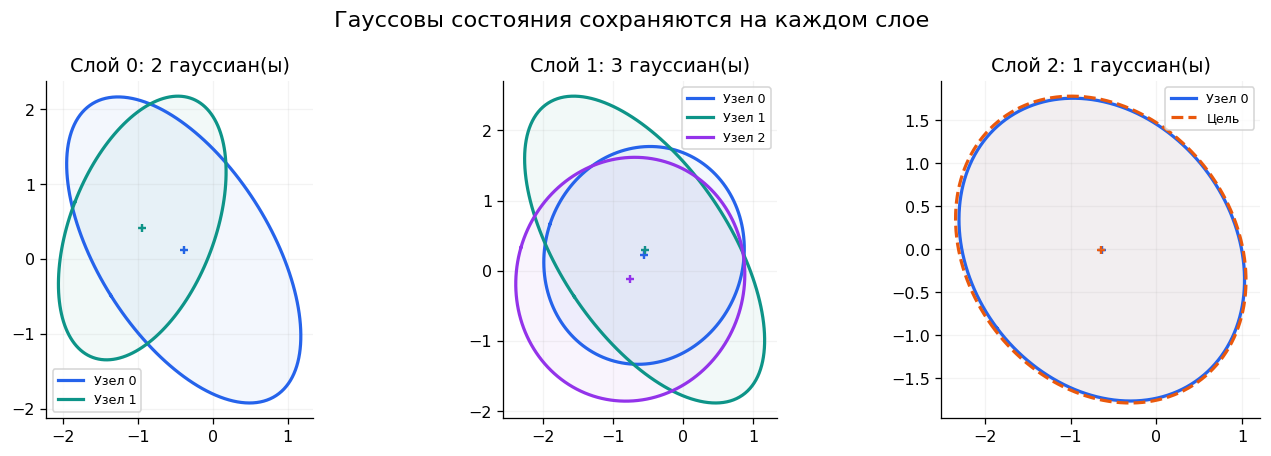

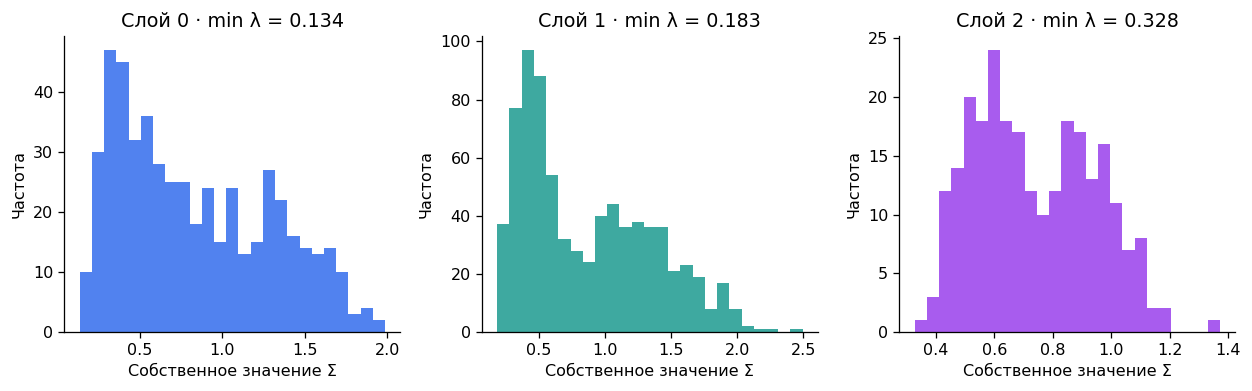

In [11]:
def ellipse_points(mu,cov,radius=2.):
    mu=np.asarray(mu);cov=np.asarray(cov)
    ev,Q=np.linalg.eigh(cov)
    angle=np.linspace(0,2*np.pi,160)
    circle=np.stack([np.cos(angle),np.sin(angle)])
    return mu[:,None]+radius*(Q*np.sqrt(ev))@circle

def draw_ellipse(ax,mu,cov,color,label=None,ls='-',alpha=0.05):
    pts=ellipse_points(mu,cov)
    ax.plot(*pts,color=color,lw=2,ls=ls,label=label)
    ax.fill(*pts,color=color,alpha=alpha)
    ax.scatter(*mu,color=color,s=30,marker='+')

with torch.no_grad():
    predicted=model(*test[0])
    states=model(test[0][0][:128],test[0][1][:128],return_states=True)
to_np=lambda x:x.detach().cpu().numpy()
fig,axes=plt.subplots(2,3,figsize=(12,7.5))
for idx,ax in enumerate(axes.flat):
    for i in range(2):
        draw_ellipse(ax,to_np(test[0][0][idx,i]),to_np(test[0][1][idx,i]),'#94A3B8',f'Вход {i+1}',ls=':')
    draw_ellipse(ax,to_np(test[1][0][idx,0]),to_np(test[1][1][idx,0]),BLUE,'Цель',ls='--')
    draw_ellipse(ax,to_np(predicted[0][idx,0]),to_np(predicted[1][idx,0]),ORANGE,'Прогноз')
    a,b=w2_parts(predicted[0][idx],predicted[1][idx],test[1][0][idx],test[1][1][idx])
    ax.set_title(f'Test #{idx} · W₂²={(a+b).item():.4f}')
    ax.set_aspect('equal');ax.grid(alpha=0.15)
axes[0,0].legend(fontsize=8)
fig.suptitle('Первые шесть тестовых примеров, без отбора по качеству',fontsize=14)
plt.tight_layout();plt.show()

example=0
fig,axes=plt.subplots(1,3,figsize=(12,4))
colors=[BLUE,GREEN,'#9333EA']
for layer,(ax,(mu,cov)) in enumerate(zip(axes,states)):
    for j in range(mu.shape[1]):
        draw_ellipse(ax,to_np(mu[example,j]),to_np(cov[example,j]),colors[j%3],f'Узел {j}')
    if layer==2:
        draw_ellipse(ax,to_np(test[1][0][example,0]),to_np(test[1][1][example,0]),ORANGE,'Цель',ls='--')
    ax.set_title(f'Слой {layer}: {mu.shape[1]} гауссиан(ы)')
    ax.set_aspect('equal');ax.grid(alpha=0.15);ax.legend(fontsize=8)
fig.suptitle('Гауссовы состояния сохраняются на каждом слое',fontsize=14)
plt.tight_layout();plt.show()

fig,axes=plt.subplots(1,3,figsize=(11,3.5))
for i,(ax,(_,cov)) in enumerate(zip(axes,states)):
    ev=to_np(torch.linalg.eigvalsh(cov)).ravel()
    ax.hist(ev,bins=25,color=colors[i],alpha=0.8)
    ax.set_title(f'Слой {i} · min λ = {ev.min():.3f}')
    ax.set_xlabel('Собственное значение Σ');ax.set_ylabel('Частота')
plt.tight_layout();plt.show()



## 8. Какие сплайны выучились

Показываем пять функций одного внешнего ребра, определяющих первый компонент сдвига.
Это зависимости от преобразованных координат входной гауссианы.
Отдельные кривые не уникальны: константы могут перераспределяться между слагаемыми и bias.
Их не следует интерпретировать как причинный вклад признака.

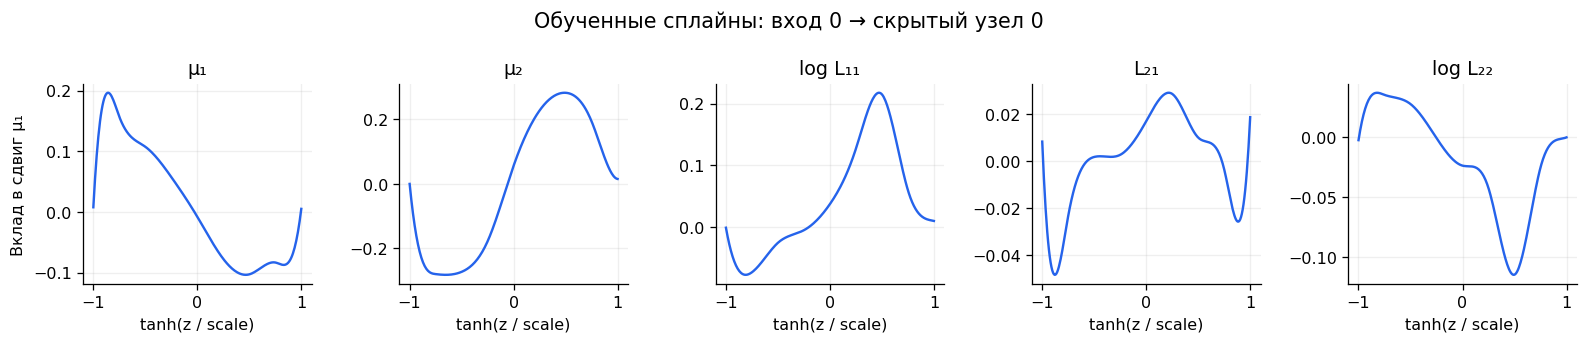

Слой 0, нормы градиентов по внешним рёбрам:
 [[0.00137639 0.00121602]
 [0.00213876 0.00181284]
 [0.00178632 0.00174092]]
Слой 1, нормы градиентов по внешним рёбрам:
 [[0.00348974 0.00377952 0.00355759]]


In [12]:
# Пять скалярных вкладов в q0 (сдвиг μ1) на одном выбранном внешнем ребре.
layer=model.layers[0]
t=torch.linspace(-0.999,0.999,250,device=DEVICE)
with torch.no_grad():
    values=layer.basis(t)
    curves=torch.einsum('tk,qk->qt',values,layer.coeff[0,0,0])
labels=['μ₁','μ₂','log L₁₁','L₂₁','log L₂₂']
fig,axes=plt.subplots(1,5,figsize=(14,3))
for i,ax in enumerate(axes):
    ax.plot(to_np(t),to_np(curves[i]),color=BLUE)
    ax.set(title=labels[i],xlabel='tanh(z / scale)');ax.grid(alpha=0.2)
axes[0].set_ylabel('Вклад в сдвиг μ₁')
fig.suptitle('Обученные сплайны: вход 0 → скрытый узел 0',fontsize=13)
plt.tight_layout();plt.show()

# Дополнительная проверка градиентов до всех рёбер после обучения.
model.zero_grad(set_to_none=True)
probe=model(train[0][0][:32],train[0][1][:32])
gaussian_loss(probe,(train[1][0][:32],train[1][1][:32])).backward()
for i,layer in enumerate(model.layers):
    norms=layer.coeff.grad.square().sum(dim=(-1,-2,-3)).sqrt()
    assert torch.isfinite(norms).all()
    print(f'Слой {i}, нормы градиентов по внешним рёбрам:\n',to_np(norms))
model.zero_grad(set_to_none=True)



## 9. Как интерпретировать результат и что менять дальше

Если независимая тестовая ошибка снижается, это подтверждает работоспособность **этой реализации
на этой синтетике**, а не преимущество архитектуры в целом. После запуска смотрите обе части ошибки,
train/validation gap, спектр ковариаций и неудачные примеры.

Следующие контролируемые эксперименты:
1. Несколько seed и сопоставимые по бюджету MLP / обычный координатный KAN.
2. Замена только агрегации на BW-барицентр при неизменных рёбрах.
3. Зависимость от ковариации, ширины и глубины, OOD-диапазоны.
4. Только после этого 3D и деформации с кондиционированием.

**Ограничения v1:** 2D; один seed; фиксированные роли входов; фиксированная сетка сплайнов;
арифметическая агрегация; ограниченные элементы S; нет обучения графа и нет проверки новизны.
При изменении глубины SPD в точной арифметике не исключает плохую обусловленность; мониторинг нужен заново.

## Источники

- [Liu et al., KAN](https://arxiv.org/abs/2404.19756): обучаемые одномерные функции на рёбрах.
- [Bhatia, Jain, Lim, BW](https://arxiv.org/abs/1712.01504): геометрия ковариаций и транспорт.
- [PyTorch matrix_exp](https://docs.pytorch.org/docs/stable/generated/torch.linalg.matrix_exp.html),
  [Cholesky](https://docs.pytorch.org/docs/stable/generated/torch.linalg.cholesky.html).

Архитектура этой тетрадки — рабочее предложение; перечисленные источники не доказывают её новизну.